In [1]:
%matplotlib inline
from matplotlib import pyplot as plt
import numpy as np

In [2]:
# each point is length, width, type (0, 1)

# training dataset
data = [[3,   1.5, 1],
        [2,   1,   0],
        [4,   1.5, 1],
        [3,   1,   0],
        [3.5, .5,  1],
        [2,   .5,  0],
        [5.5,  1,  1],
        [1,    1,  0]]

# testing dataset
mystery_flower = [4.5, 1]
mystery_flower2 = [2, 1.5]

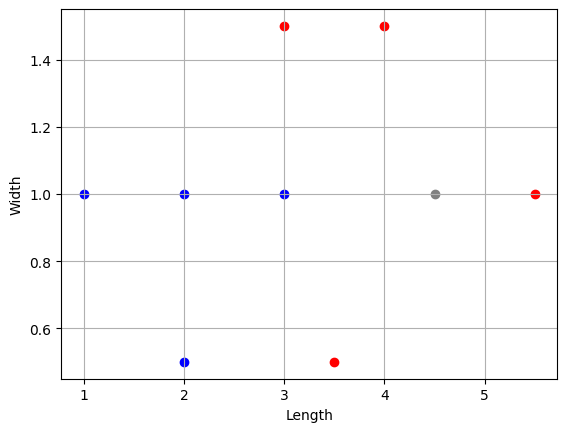

In [3]:
# scatter plot them
def vis_data():
    plt.grid()
    plt.xlabel("Length")
    plt.ylabel("Width")

    for i in range(len(data)):
        c = 'r' # 1 -> red
        if data[i][2] == 0:
            c = 'b' # 0 -> blue
        plt.scatter([data[i][0]], [data[i][1]], c=c)

    plt.scatter([mystery_flower[0]], [mystery_flower[1]], c='gray')

vis_data()

In [4]:
# network

#       o  flower type
#      / \  w1, w2, b
#     o   o  length, width

In [5]:
# activation function

def sigmoid(x):
    return 1/(1+np.exp(-x))

def sigmoid_p(x):
    return sigmoid(x) * (1-sigmoid(x))

Text(0, 0.5, "sigmoid(x) / sigmoid'(x)")

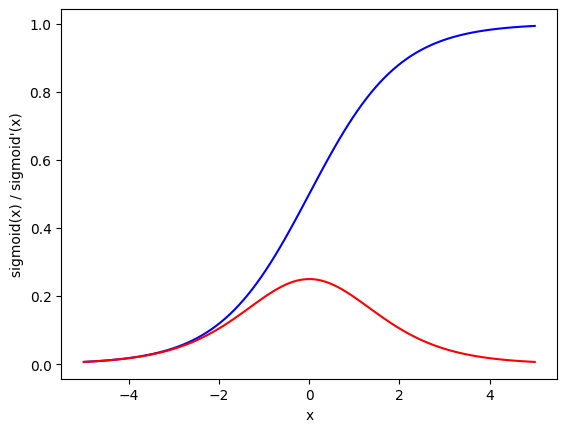

In [6]:
X = np.linspace(-5, 5, 100)

plt.plot(X, sigmoid(X), c="b") # sigmoid in blue
fig = plt.plot(X, sigmoid_p(X), c="r") # sigmoid_p in red
plt.xlabel("x")
plt.ylabel("sigmoid(x) / sigmoid'(x)")

initial cost: 3.8853249438962396
final cost: 0.5088533712987358
final weights: 2.7307643636232997 0.963314870636422
final bias: -8.45174020346898


Text(0, 0.5, 'Total cost over all data points')

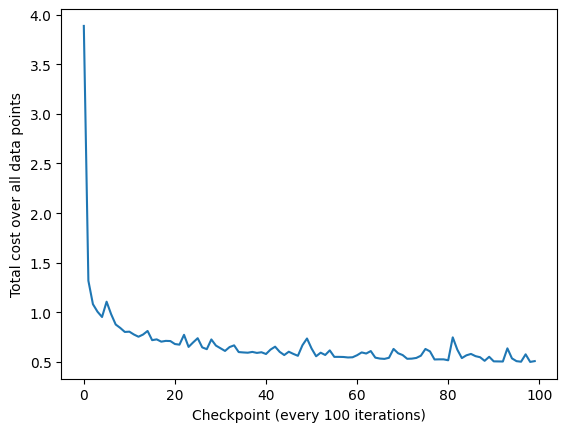

In [7]:
# train

def train():
    # random init of weights
    w1 = np.random.randn()  # weight for the length input
    w2 = np.random.randn()  # weight for the width input
    b = np.random.randn()   # bias term

    iterations = 10000       # number of training steps (one random data point per step)
    learning_rate = 0.1      # step size for gradient descent updates
    costs = [] # keep costs during training, see if they go down

    for i in range(iterations):
        # get a random point
        ri = np.random.randint(len(data))  # pick a random index into the dataset
        point = data[ri]                    # the sampled (length, width, type) point

        z = point[0] * w1 + point[1] * w2 + b  # weighted sum (pre-activation) for this point
        pred = sigmoid(z) # networks prediction

        target = point[2]  # the true label (0 or 1) for this point

        # cost for current random point
        cost = np.square(pred - target)  # squared error between prediction and target

        # print the cost over all data points every 100 iters
        if i % 100 == 0:
            c = 0  # accumulator for total cost across the whole dataset
            for j in range(len(data)):
                p = data[j]  # j-th data point
                p_pred = sigmoid(w1 * p[0] + w2 * p[1] + b)  # prediction for that point with current weights
                c += np.square(p_pred - p[2])  # add its squared error to the running total
            costs.append(c)  # record the total cost at this checkpoint

        dcost_dpred = 2 * (pred - target)  # derivative of squared-error cost w.r.t. the prediction
        dpred_dz = sigmoid_p(z)             # derivative of sigmoid w.r.t. z (chain rule step)

        dz_dw1 = point[0]  # derivative of z w.r.t. w1 is just the length input
        dz_dw2 = point[1]  # derivative of z w.r.t. w2 is just the width input
        dz_db = 1          # derivative of z w.r.t. the bias is always 1

        dcost_dz = dcost_dpred * dpred_dz  # chain rule: dcost/dz = dcost/dpred * dpred/dz

        dcost_dw1 = dcost_dz * dz_dw1  # chain rule: gradient of cost w.r.t. w1
        dcost_dw2 = dcost_dz * dz_dw2  # chain rule: gradient of cost w.r.t. w2
        dcost_db = dcost_dz * dz_db    # chain rule: gradient of cost w.r.t. b

        w1 = w1 - learning_rate * dcost_dw1  # gradient descent update for w1
        w2 = w2 - learning_rate * dcost_dw2  # gradient descent update for w2
        b = b - learning_rate * dcost_db      # gradient descent update for b

    return costs, w1, w2, b  # return the cost history and the learned parameters

costs, w1, w2, b = train()  # run training and unpack the learned parameters
print("initial cost:", costs[0])
print("final cost:", costs[-1])
print("final weights:", w1, w2)
print("final bias:", b)
fig = plt.plot(costs)
plt.xlabel("Checkpoint (every 100 iterations)")
plt.ylabel("Total cost over all data points")

In [8]:
# predict what the myster flower is!

z = w1 * mystery_flower[0] + w2 * mystery_flower[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.9918375446461302
close to 0 -> blue, close to 1 -> red


In [9]:
# predict what the myster flower2 is!

z = w1 * mystery_flower2[0] + w2 * mystery_flower2[1] + b
pred = sigmoid(z)

print(pred)
print("close to 0 -> blue, close to 1 -> red")

0.17577494386483944
close to 0 -> blue, close to 1 -> red


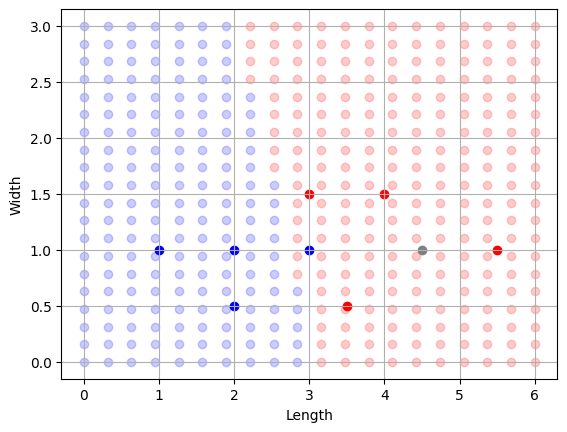

In [10]:
# check out the networks predictions in the x,y plane
for x in np.linspace(0, 6, 20):
    for y in np.linspace(0, 3, 20):
        pred = sigmoid(w1 * x + w2 * y + b)
        c = 'b'
        if pred > .5:
            c = 'r'
        plt.scatter([x],[y],c=c, alpha=.2)

# plot points over network predictions
# you should see a split, with half the predictions blue
# and the other half red.. nicely predicting each data point!
vis_data()

# Word2Vec Skip-gram

WORD2VEC-SKIPGRAM(Corpus, c, d, η, T)
1. Build vocabulary V from the corpus
2. Initialize input embeddings E randomly
3. Initialize output weights W randomly
4. Generate training pairs (center, context) within window c
5. For epoch = 1 to T: shuffle pairs; for each pair do forward pass, loss, backprop, update
6. Return E

In [50]:
# Steps 1-3: vocabulary, embeddings E, output weights W
corpus = [
    "the cat sat on the mat",
    "the dog sat on the log",
    "the cat chased the rat",
    "the dog chased the cat",
]

c = 2        # context window size
d = 10       # embedding dimension
eta = 0.05   # learning rate
T = 200      # epochs

sentences = [s.split() for s in corpus]
vocab = sorted({w for s in sentences for w in s})
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
V = len(vocab)

E = np.random.randn(V, d) * 0.1   # input embeddings, one row per word
W = np.random.randn(d, V) * 0.1   # output weights

In [51]:
print("Input Embeddings:", E)

Input Embeddings: [[ 0.05517972  0.0084907   0.00878749 -0.16076026  0.16610466  0.00137188
   0.16421789  0.05888705 -0.01877278  0.18458691]
 [ 0.05139441 -0.19294467 -0.11546023 -0.01376226 -0.04355343 -0.12355085
   0.00406722  0.0689719   0.02252752  0.17403925]
 [ 0.05170755  0.0132141   0.05200458  0.02322275  0.02739462  0.00899512
  -0.06202132  0.16662716 -0.20187041  0.07976504]
 [-0.06030376  0.06793637  0.01908549 -0.01422911 -0.11480901  0.06435537
   0.07846642 -0.17409464 -0.07289225  0.08617836]
 [-0.01101376 -0.19600595 -0.03537601  0.11428637 -0.18074328 -0.03055074
  -0.02419717  0.05881125 -0.05879652  0.1660839 ]
 [-0.06862177 -0.04908472 -0.13938283 -0.0606182   0.04087134 -0.13898839
  -0.06589315  0.01458603  0.0453698   0.2404506 ]
 [-0.09361297  0.07355081 -0.05343799  0.01018816 -0.26221032  0.07388366
  -0.16731904  0.01404046 -0.01956651  0.216706  ]
 [ 0.0065134   0.01495676  0.05968349 -0.06643194 -0.00532863 -0.03142179
   0.20630918  0.0208468   0.0663

In [52]:
# Step 4: generate training pairs
def make_pairs(sentences, c):
    pairs = []
    pair_words = []
    for sentence in sentences:
        for i, w in enumerate(sentence):
            for j in range(max(0, i - c), min(len(sentence), i + c + 1)):
                if i != j:
                    pairs.append((word2idx[w], word2idx[sentence[j]]))
                    pair_words.append((w, sentence[j]))
    return pairs, pair_words

pairs, pair_words = make_pairs(sentences, c)
print(pairs)
print(pair_words)
print(len(pairs), "training pairs")

[(8, 0), (8, 7), (0, 8), (0, 7), (0, 5), (7, 8), (7, 0), (7, 5), (7, 8), (5, 0), (5, 7), (5, 8), (5, 4), (8, 7), (8, 5), (8, 4), (4, 5), (4, 8), (8, 2), (8, 7), (2, 8), (2, 7), (2, 5), (7, 8), (7, 2), (7, 5), (7, 8), (5, 2), (5, 7), (5, 8), (5, 3), (8, 7), (8, 5), (8, 3), (3, 5), (3, 8), (8, 0), (8, 1), (0, 8), (0, 1), (0, 8), (1, 8), (1, 0), (1, 8), (1, 6), (8, 0), (8, 1), (8, 6), (6, 1), (6, 8), (8, 2), (8, 1), (2, 8), (2, 1), (2, 8), (1, 8), (1, 2), (1, 8), (1, 0), (8, 2), (8, 1), (8, 0), (0, 1), (0, 8)]
[('the', 'cat'), ('the', 'sat'), ('cat', 'the'), ('cat', 'sat'), ('cat', 'on'), ('sat', 'the'), ('sat', 'cat'), ('sat', 'on'), ('sat', 'the'), ('on', 'cat'), ('on', 'sat'), ('on', 'the'), ('on', 'mat'), ('the', 'sat'), ('the', 'on'), ('the', 'mat'), ('mat', 'on'), ('mat', 'the'), ('the', 'dog'), ('the', 'sat'), ('dog', 'the'), ('dog', 'sat'), ('dog', 'on'), ('sat', 'the'), ('sat', 'dog'), ('sat', 'on'), ('sat', 'the'), ('on', 'dog'), ('on', 'sat'), ('on', 'the'), ('on', 'log'), ('th

Text(0, 0.5, 'average loss')

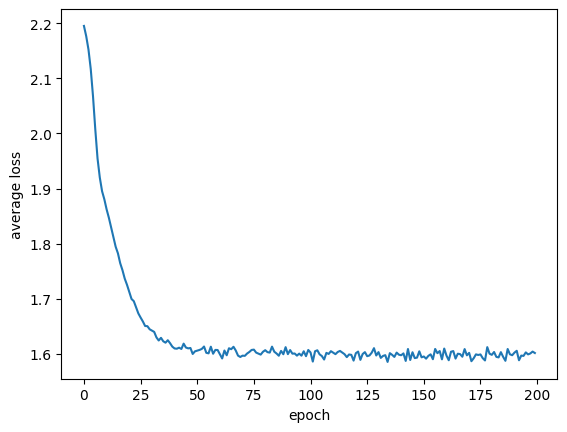

In [53]:
# Step 5: training loop
def softmax(x):
    e = np.exp(x - np.max(x))
    return e / e.sum()

def train_word2vec(E, W, pairs, eta, T):
    losses = []
    for epoch in range(T):
        np.random.shuffle(pairs)
        total_loss = 0
        for center, context in pairs:
            # forward pass
            h = E[center]
            scores = h @ W
            probabilities = softmax(scores)

            # loss
            loss = -np.log(probabilities[context])
            total_loss += loss

            # backpropagation
            error = probabilities.copy()
            error[context] -= 1

            gradient_W = np.outer(h, error)
            gradient_h = W @ error

            # update parameters
            W -= eta * gradient_W
            E[center] -= eta * gradient_h
        losses.append(total_loss / len(pairs))
    return E, losses

E, losses = train_word2vec(E, W, pairs, eta, T)

plt.plot(losses)
plt.xlabel("epoch")
plt.ylabel("average loss")

In [54]:
# dimension of each word vector
print("E shape:", E.shape)                  # (vocab size, dimension)
print("Dimension per word:", E.shape[1])    # same as d

for word, idx in word2idx.items():
    print(word, "->", E[idx])         # each vector is (d,)

E shape: (9, 10)
Dimension per word: 10
cat -> [ 0.811723    0.39314244 -0.68191072 -0.32468739  0.6697182  -0.32926879
 -0.31602487  0.86614821 -0.55044222  0.95493949]
chased -> [-0.44211532 -1.40699155 -0.2878283  -0.06433098 -0.39353335 -0.46410453
  0.28903951 -0.69213441  0.57472459  1.33485159]
dog -> [ 0.69004259  0.39964533 -0.81381533 -0.33935525  0.5879056  -0.51051047
 -0.18392162  0.96077274 -0.57436765  0.73743755]
log -> [ 0.09928152  0.81945104 -0.61998281 -0.40935194  0.33934876 -0.82374532
  1.12177271 -0.43213044 -0.63518109  1.18777094]
mat -> [ 0.18910871  0.76420781 -0.66212639 -0.31151072  0.35573352 -0.92581977
  1.11375223 -0.27463782 -0.69913243  1.25872857]
on -> [-0.63039979 -0.84913248 -0.8899869  -0.8037519  -0.4774179  -0.24792077
 -0.21462721  0.89949538  0.22216805 -0.20076418]
rat -> [ 1.05848504 -0.01228151 -0.34350002 -0.38433147  0.49148542  0.47326607
 -1.01273292  0.23658006 -0.63599165  1.9929979 ]
sat -> [-0.83217307  0.12513795 -0.34506055 -0.0

In [57]:
# Step 6: return E, check similar words
def most_similar(word, topn=3):
    v = E[word2idx[word]]
    sims = E @ v / (np.linalg.norm(E, axis=1) * np.linalg.norm(v) + 1e-9)
    order = np.argsort(-sims)
    return [(idx2word[i], round(float(sims[i]), 3)) for i in order if idx2word[i] != word][:topn]

print(most_similar("cat"))
print(most_similar("mat"))

[('dog', 0.982), ('rat', 0.77), ('mat', 0.541)]
[('log', 0.994), ('sat', 0.699), ('dog', 0.569)]


In [58]:
# Final V x V matrix: every word's similarity score with every other word
# (cosine similarity between the final word embeddings in E)
E_norm = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)   # unit-length rows
sim_matrix = E_norm @ E_norm.T                                    # shape (V, V)

print(f"Final similarity matrix: {sim_matrix.shape[0]} x {sim_matrix.shape[1]}  (V = {V})\n")
print(" " * 8 + "".join(f"{w:>8}" for w in vocab))
for i, w in enumerate(vocab):
    print(f"{w:<8}" + "".join(f"{sim_matrix[i, j]:8.3f}" for j in range(V)))

Final similarity matrix: 9 x 9  (V = 9)

             cat  chased     dog     log     mat      on     rat     sat     the
cat        1.000  -0.117   0.982   0.481   0.541   0.081   0.770   0.123  -0.202
chased    -0.117   1.000  -0.148   0.208   0.209   0.281   0.176   0.589  -0.343
dog        0.982  -0.148   1.000   0.505   0.569   0.182   0.647   0.182  -0.191
log        0.481   0.208   0.505   1.000   0.994  -0.189   0.286   0.694  -0.460
mat        0.541   0.209   0.569   0.994   1.000  -0.167   0.320   0.699  -0.421
on         0.081   0.281   0.182  -0.189  -0.167   1.000  -0.096   0.190  -0.219
rat        0.770   0.176   0.647   0.286   0.320  -0.096   1.000  -0.031  -0.327
sat        0.123   0.589   0.182   0.694   0.699   0.190  -0.031   1.000  -0.101
the       -0.202  -0.343  -0.191  -0.460  -0.421  -0.219  -0.327  -0.101   1.000


In [59]:
# Final V x V matrix: probability of each word (column) appearing as context of each word (row)
# row i = softmax(E[i] @ W), i.e. the model's P(context word | center word i); every row sums to 1
scores = E @ W                                                      # raw scores, shape (V, V)
prob_matrix = np.array([softmax(row) for row in scores])           # softmax applied row by row

print(f"Final probability matrix: {prob_matrix.shape[0]} x {prob_matrix.shape[1]}  (V = {V})\n")
print("row = center word, column = context word\n")
print(" " * 8 + "".join(f"{w:>8}" for w in vocab) + "     row sum")
for i, w in enumerate(vocab):
    print(f"{w:<8}" + "".join(f"{prob_matrix[i, j]:8.3f}" for j in range(V)) + f"{prob_matrix[i].sum():12.3f}")

Final probability matrix: 9 x 9  (V = 9)

row = center word, column = context word

             cat  chased     dog     log     mat      on     rat     sat     the     row sum
cat        0.005   0.273   0.005   0.003   0.003   0.140   0.001   0.131   0.439       1.000
chased     0.232   0.004   0.118   0.004   0.005   0.010   0.140   0.003   0.483       1.000
dog        0.006   0.185   0.007   0.003   0.004   0.171   0.001   0.171   0.452       1.000
log        0.004   0.010   0.006   0.001   0.001   0.524   0.003   0.003   0.448       1.000
mat        0.004   0.011   0.005   0.000   0.000   0.507   0.002   0.003   0.468       1.000
on         0.124   0.009   0.128   0.124   0.125   0.010   0.008   0.239   0.233       1.000
rat        0.002   0.481   0.002   0.001   0.001   0.020   0.004   0.021   0.468       1.000
sat        0.130   0.005   0.124   0.002   0.002   0.244   0.006   0.008   0.479       1.000
the        0.226   0.162   0.170   0.051   0.051   0.089   0.049   0.191   0.01